# Notebook 06 - Category Sales Prediction

**Model**: `category_sales_predictor.pkl`  
**Algorithm**: Multi-Output Random Forest Regressor  
**Target**: Next month's unit sales for every department (21 outputs simultaneously)  
**Input Features**: Current + lagged monthly department sales vectors

In [1]:
# What: Import multi-output regression and visualization libraries
# Why: MultiOutputRegressor wraps any sklearn regressor to handle vector targets
# Method: sklearn MultiOutputRegressor + RandomForestRegressor + seaborn for charts
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

DATA_PATH    = '../data'
MODELS_PATH  = '../models'
RANDOM_STATE = 42
os.makedirs(MODELS_PATH, exist_ok=True)

# Department avg price proxy (Rs.) — consistent across all notebooks
DEPT_PRICE = {1:350,2:200,3:250,4:150,5:800,6:400,7:180,8:600,9:300,
              10:200,11:500,12:700,13:350,14:280,15:200,16:300,17:450,
              18:500,19:220,20:400,21:200}
print('Config loaded')

Config loaded


In [2]:
# What: Load required dataset files
# Why: Need products+departments to map items to categories; orders for timing
# Method: pandas read_csv with shape validation
orders      = pd.read_csv(f'{DATA_PATH}/orders.csv')
op_train    = pd.read_csv(f'{DATA_PATH}/order_products__train.csv')
products    = pd.read_csv(f'{DATA_PATH}/products.csv')
departments = pd.read_csv(f'{DATA_PATH}/departments.csv')

print(f'orders: {orders.shape} | op_train: {op_train.shape}')
print(f'products: {products.shape} | departments: {departments.shape}')

orders: (3421083, 7) | op_train: (1384617, 4)
products: (49688, 4) | departments: (21, 2)


In [3]:
# What: Merge all tables into a single item-level dataset
# Why: Need department_id + order_number per item to compute monthly category sales
# Method: Left joins: op_train → products → orders; assign month_num
products_dept = products.merge(departments, on='department_id', how='left')
order_items = op_train.merge(products_dept[['product_id','department_id']], on='product_id', how='left')
order_items = order_items.merge(
    orders[['order_id','order_number']],
    on='order_id', how='left'
)
order_items['month_num'] = np.ceil(order_items['order_number'] / 3).astype(int)
order_items['units_sold'] = 1  # each row = 1 unit added to cart

print('Merged item table:', order_items.shape)
print(order_items[['order_id','department_id','month_num','units_sold']].head())

Merged item table: (1384617, 8)
   order_id  department_id  month_num  units_sold
0         1             16          2           1
1         1             16          2           1
2         1              4          2           1
3         1              4          2           1
4         1             15          2           1


In [4]:
# What: Compute monthly units sold per department (pivot table)
# Why: Multi-output target = next month's units per department (21 values)
# Method: groupby (month_num, department_id) → count units → pivot to wide format
month_dept_units = order_items.groupby(['month_num','department_id'])['units_sold'].sum().reset_index()

# Pivot to wide format: rows = months, columns = department unit sales
pivot = month_dept_units.pivot_table(
    index='month_num', columns='department_id',
    values='units_sold', fill_value=0
)
pivot.columns = [f'dept_{c}_units' for c in pivot.columns]
pivot.reset_index(inplace=True)

print(f'Pivot table: {pivot.shape} — {len(pivot)} months × {len(pivot.columns)-1} departments')
print(pivot.head(3).to_string())

Pivot table: (33, 22) — 33 months × 21 departments
   month_num  dept_1_units  dept_2_units  dept_3_units  dept_4_units  dept_5_units  dept_6_units  dept_7_units  dept_8_units  dept_9_units  dept_10_units  dept_11_units  dept_12_units  dept_13_units  dept_14_units  dept_15_units  dept_16_units  dept_17_units  dept_18_units  dept_19_units  dept_20_units  dept_21_units
0          2       29175.0         542.0       13455.0      107484.0        1848.0        3423.0       31068.0        1300.0       11352.0          320.0         6080.0         8773.0        23500.0         8360.0        14220.0        58220.0        10356.0         3525.0        31799.0        11977.0         1981.0
1          3       17758.0         337.0        8126.0       67683.0         997.0        2065.0       19011.0         740.0        6869.0          208.0         3912.0         5339.0        14234.0         5025.0         8499.0        36379.0         6385.0         2220.0        20147.0         7721.0        

In [5]:
# What: Add revenue-based features alongside unit counts
# Why: Revenue provides a weighted signal (high-price departments matter more than unit count alone)
# Method: Repeat groupby with revenue = units × price, merge onto pivot table
order_items['revenue'] = order_items['department_id'].map(DEPT_PRICE).fillna(200)
month_dept_rev = order_items.groupby(['month_num','department_id'])['revenue'].sum().reset_index()
pivot_rev = month_dept_rev.pivot_table(
    index='month_num', columns='department_id',
    values='revenue', fill_value=0
)
pivot_rev.columns = [f'dept_{c}_rev' for c in pivot_rev.columns]
pivot_rev.reset_index(inplace=True)

# Merge unit and revenue pivots
pivot = pivot.merge(pivot_rev, on='month_num', how='left')
print(f'Combined feature table: {pivot.shape}')

Combined feature table: (33, 43)


In [6]:
# What: Create lag features (previous month's department sales as predictors)
# Why: This month's category sales strongly predict next month — temporal dependency
# Method: shift(1) all unit columns to create X features; original = Y targets
unit_cols = [c for c in pivot.columns if c.endswith('_units')]
rev_cols  = [c for c in pivot.columns if c.endswith('_rev')]

for col in unit_cols + rev_cols:
    pivot[f'prev_{col}'] = pivot[col].shift(1)

pivot.dropna(inplace=True)  # remove first row (no lag)
print(f'After lag engineering: {pivot.shape}')
print(f'Units columns: {len(unit_cols)} | Rev columns: {len(rev_cols)}')

After lag engineering: (32, 85)
Units columns: 21 | Rev columns: 21


In [7]:
# What: Prepare X (features) and Y (multi-output targets)
# Why: Features = current month sales; Y = same month's unit sales (we train to predict next)
# Method: X = lag features; Y = current unit_cols (the "future" relative to lags)
feature_cols = [f'prev_{c}' for c in unit_cols + rev_cols]
X = pivot[feature_cols].values   # previous month's dept sales
Y = pivot[unit_cols].values      # current month's dept unit sales (target)

# Split preserving temporal order — don't shuffle time-series data
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=RANDOM_STATE, shuffle=False)
print(f'Train: X={X_train.shape}, Y={Y_train.shape}')
print(f'Test : X={X_test.shape}, Y={Y_test.shape}')

Train: X=(25, 42), Y=(25, 21)
Test : X=(7, 42), Y=(7, 21)


In [9]:
# What: Train Multi-Output Random Forest Regressor
# Why: Predicts all 21 department unit sales simultaneously; preserves inter-department correlations
# Method: MultiOutputRegressor wraps RF — trains one RF per output column (21 RFs total)
base_rf = RandomForestRegressor(
    n_estimators   = 200,
    min_samples_leaf = 3,
    max_features   = 'sqrt',
    random_state   = RANDOM_STATE,
    n_jobs         = -1
)

model = MultiOutputRegressor(base_rf, n_jobs=-1)
model.fit(X_train, Y_train)
print('Multi-output training complete')
print(f'Number of estimators (one per dept): {len(model.estimators_)}')

Multi-output training complete
Number of estimators (one per dept): 21


In [10]:
# What: Evaluate model — per-department RMSE and overall R²
# Why: Multi-output model needs evaluation per output to identify weak departments
# Method: Compute RMSE per column, overall average R² across all 21 outputs
Y_pred = model.predict(X_test)

dept_rmse = []
for i, col in enumerate(unit_cols):
    dept_id   = int(col.split('_')[1])
    dept_name = departments[departments['department_id']==dept_id]['department'].values
    dept_name = dept_name[0] if len(dept_name) else f'dept_{dept_id}'
    rmse_i    = np.sqrt(mean_squared_error(Y_test[:, i], Y_pred[:, i]))
    r2_i      = r2_score(Y_test[:, i], Y_pred[:, i]) if Y_test[:, i].std() > 0 else 0
    dept_rmse.append({'department': dept_name, 'rmse': rmse_i, 'r2': r2_i})

rmse_df = pd.DataFrame(dept_rmse).sort_values('r2', ascending=False)
print('Per-Department Performance:')
print(rmse_df[['department','rmse','r2']].to_string(index=False))
print(f'\nOverall Avg R²  : {rmse_df["r2"].mean():.4f}')
print(f'Overall Avg RMSE: {rmse_df["rmse"].mean():,.0f} units')

Per-Department Performance:
     department       rmse        r2
          other   3.348727 -0.021347
           bulk   4.799810 -0.022528
        alcohol   9.198974 -0.036609
         pantry 156.680392 -0.344526
     dairy eggs 457.383474 -0.357962
        produce 883.418986 -0.407281
      beverages 244.108559 -0.461283
           deli  73.691227 -0.507521
         bakery 104.965343 -0.528428
         snacks 240.791680 -0.597176
      breakfast  51.645028 -0.720871
      household  48.057503 -0.893622
  personal care  33.366312 -0.972100
dry goods pasta  64.482682 -1.002662
   meat seafood  49.628028 -1.007053
   canned goods  71.241647 -1.172714
         frozen 151.108238 -1.182247
         babies  35.956092 -1.274167
  international  20.816189 -1.503227
           pets   7.149666 -1.865868
        missing  22.320557 -7.389057

Overall Avg R²  : -1.0604
Overall Avg RMSE: 130 units


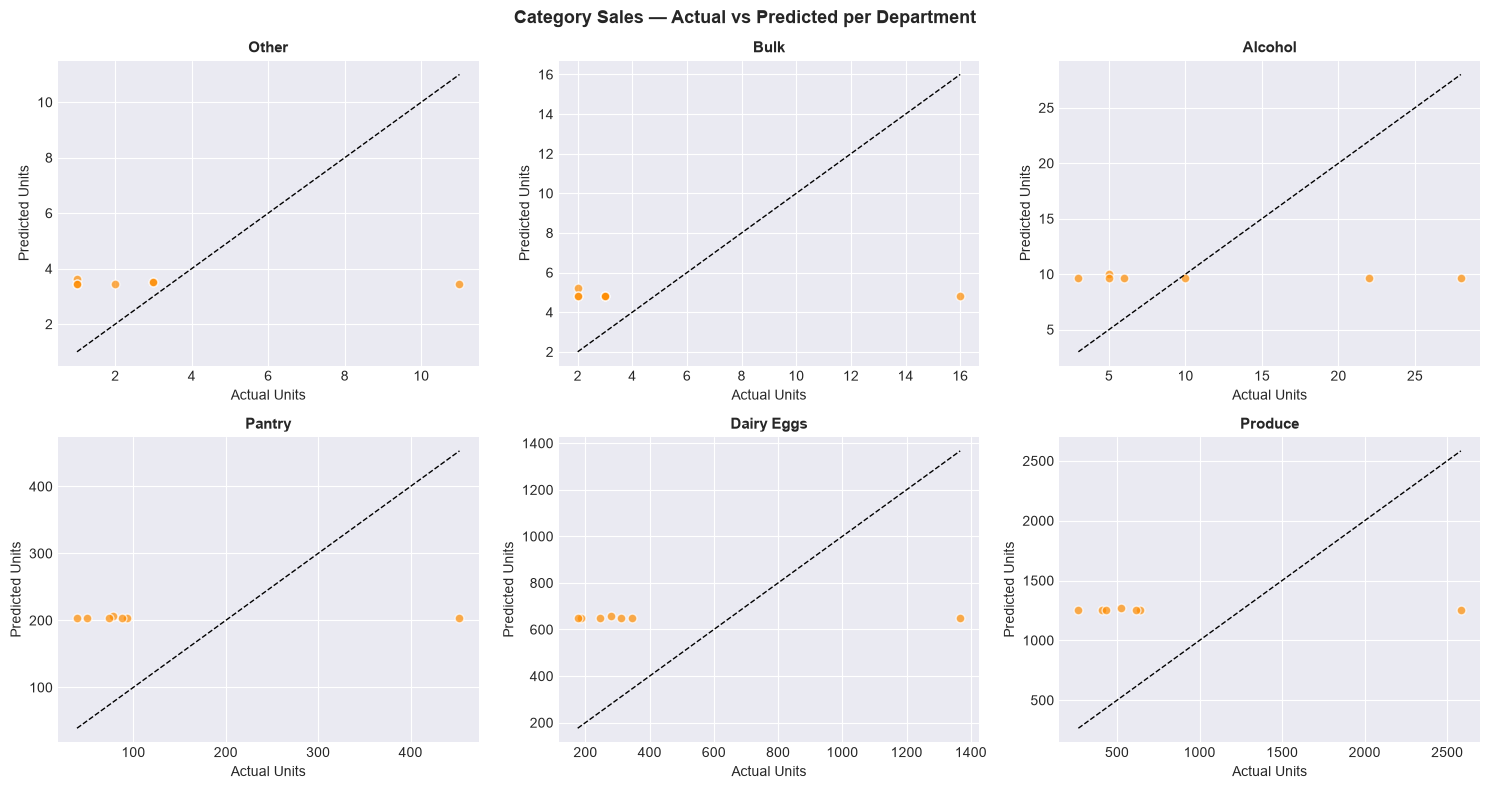

Chart saved


In [11]:
# What: Visualize predicted vs actual for top 6 departments
# Why: Check model quality per-department — identify any that need attention
# Method: Grid of scatter plots showing predicted vs actual unit sales
top6 = rmse_df.head(6)['department'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, dept_name in zip(axes.flatten(), top6):
    idx = [i for i, c in enumerate(unit_cols)
           if departments[departments['department_id']==int(c.split('_')[1])]['department'].values[0] == dept_name
           if len(departments[departments['department_id']==int(c.split('_')[1])]['department'].values)]
    if not idx:
        continue
    i = idx[0]
    ax.scatter(Y_test[:, i], Y_pred[:, i], color='darkorange', alpha=0.7, edgecolors='white', s=40)
    lims = [min(Y_test[:,i].min(), Y_pred[:,i].min()), max(Y_test[:,i].max(), Y_pred[:,i].max())]
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_title(f'{dept_name.title()}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Actual Units')
    ax.set_ylabel('Predicted Units')

plt.suptitle('Category Sales — Actual vs Predicted per Department', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{MODELS_PATH}/chart_category_sales_model.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved')

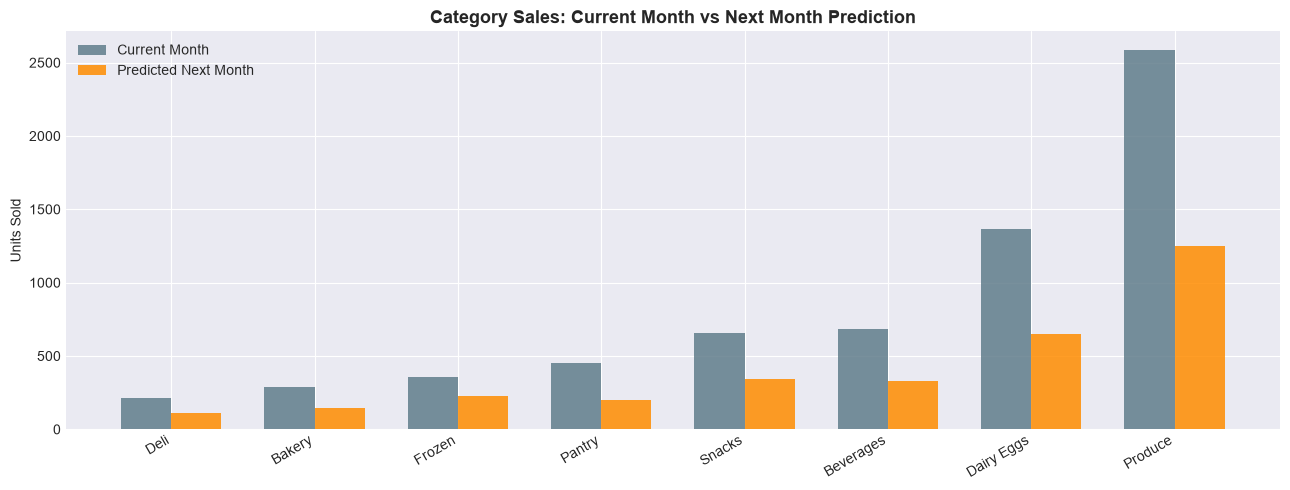

Category comparison chart saved


In [12]:
# What: Visualize current vs predicted sales by department (bar chart)
# Why: Matches the dashboard UI — show current vs next month side-by-side per category
# Method: Use last known month as current; model prediction as next month
last_features  = pivot[feature_cols].iloc[[-1]].values
next_preds     = model.predict(last_features)[0]  # next month unit sales per dept
current_units  = pivot[unit_cols].iloc[-1].values  # current month unit sales per dept

# Select top 8 departments by current sales for chart clarity
top_idx = np.argsort(current_units)[-8:]
top_dept_names = []
for i in top_idx:
    dept_id   = int(unit_cols[i].split('_')[1])
    name_arr  = departments[departments['department_id']==dept_id]['department'].values
    top_dept_names.append(name_arr[0].title() if len(name_arr) else f'Dept {dept_id}')

x = np.arange(len(top_idx))
width = 0.35
fig, ax = plt.subplots(figsize=(13, 5))
bars1 = ax.bar(x - width/2, current_units[top_idx], width, label='Current Month', color='#607D8B', alpha=0.85)
bars2 = ax.bar(x + width/2, next_preds[top_idx],    width, label='Predicted Next Month', color='darkorange', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(top_dept_names, rotation=30, ha='right')
ax.set_ylabel('Units Sold')
ax.set_title('Category Sales: Current Month vs Next Month Prediction', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(f'{MODELS_PATH}/chart_category_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Category comparison chart saved')

In [14]:
# What: Save model bundle — multi-output RF + metadata
# Why: API needs model + department mapping + feature column list for clean inference
# Method: Save as dict bundle with all inference-required components
category_bundle = {
    'model':            model,
    'feature_cols':     feature_cols,
    'unit_cols':        unit_cols,
    'departments':      departments.set_index('department_id')['department'].to_dict(),
    'last_month_units': dict(zip(unit_cols, current_units)),       # current month reference
    'next_month_pred':  dict(zip(unit_cols, next_preds.tolist()))  # pre-computed prediction
}
joblib.dump(category_bundle, f'{MODELS_PATH}/category_sales_predictor.pkl')
print('Saved: models/category_sales_predictor.pkl')
print(f'Size: {os.path.getsize(f"{MODELS_PATH}/category_sales_predictor.pkl") / 1024:.1f} KB')

Saved: models/category_sales_predictor.pkl
Size: 3707.8 KB


In [15]:
# What: Verify .pkl loads correctly and predictions are accessible
# Why: Confirm API can load and use the category sales model without issues
# Method: Load bundle, extract next_month_pred dict, print top categories
loaded = joblib.load(f'{MODELS_PATH}/category_sales_predictor.pkl')
preds  = loaded['next_month_pred']
dept_map = loaded['departments']

# Decode department names and sort by predicted units
results = []
for col, units in preds.items():
    dept_id = int(col.split('_')[1])
    name    = dept_map.get(dept_id, f'dept_{dept_id}')
    results.append({'department': name.title(), 'predicted_units': int(units)})

results_df = pd.DataFrame(results).sort_values('predicted_units', ascending=False)
print('Next Month Category Sales Prediction')
print(results_df.to_string(index=False))
print(f"\n Top Predicted Category: {results_df.iloc[0]['department']} ({results_df.iloc[0]['predicted_units']:,} units)")

Next Month Category Sales Prediction
     department  predicted_units
        Produce             1251
     Dairy Eggs              648
         Snacks              339
      Beverages              328
         Frozen              225
         Pantry              202
         Bakery              145
           Deli              110
   Canned Goods              106
Dry Goods Pasta               92
      Breakfast               80
      Household               73
   Meat Seafood               71
         Babies               61
  Personal Care               49
        Missing               32
  International               31
        Alcohol                9
           Pets                8
           Bulk                4
          Other                3

 Top Predicted Category: Produce (1,251 units)
